# Báo cáo accuracy phát hiện câu hỏi không trả lời được trên tập test

Đo **answerability** (mô hình có nhận ra câu hỏi không có đáp án hay không) của mô hình được chọn, **PhoBERT**, trên `data/processed/testing.json`, ba seed 42, 123, 1024.

- Không huấn luyện lại, không chỉnh siêu tham số: dùng nguyên `best_model/` đã chọn bằng F1 dev, ngưỡng no-answer giữ ở 0.
- Dự đoán NoAns là `prediction_text == ""` (như notebook 07). Confusion matrix: hàng là nhãn thật, cột là dự đoán, thứ tự `HasAns`, `NoAns`.
- Tỷ lệ NoAns của test khác dev nên accuracy không so trực tiếp với dev được; notebook báo thêm precision/recall/F1 NoAns, recall HasAns, balanced accuracy và dòng tham chiếu "luôn trả lời".
- Dự đoán được lưu ở `results/test/predictions/`; chạy lại sẽ dùng cache. Kết quả cuối: `results/test_answerability_metrics.json`. Cần GPU và `pip install underthesea`.

In [1]:
import hashlib
import json
import re
import sys
from math import isclose
from pathlib import Path
from statistics import mean, pstdev

import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForQuestionAnswering, AutoTokenizer
from underthesea import word_tokenize

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import decode_predictions
from src.utils import save_json


def load_jsonl(path):
    with path.open("r", encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


data_dir = project_root / "data" / "processed"
results_dir = project_root / "results"
test_path = data_dir / "testing.json"
train_examples = load_jsonl(data_dir / "train.json")
dev_examples = load_jsonl(data_dir / "dev.json")
test_examples = load_jsonl(test_path)

test_by_id = {row["id"]: row for row in test_examples}
if len(test_by_id) != len(test_examples):
    raise ValueError("testing.json có id bị lặp.")
test_ids = [row["id"] for row in test_examples]
true_no = [bool(test_by_id[i]["is_impossible"]) for i in test_ids]

# id được đánh số lại trong từng tập nên kiểm tra rò rỉ bằng cặp (câu hỏi, context).
seen = {(r["question"].strip(), r["context"].strip()) for r in train_examples + dev_examples}
leaked = sum((r["question"].strip(), r["context"].strip()) in seen for r in test_examples)

test_noans = sum(true_no)
dev_noans = sum(bool(r["is_impossible"]) for r in dev_examples)
test_sha256 = hashlib.sha256(test_path.read_bytes()).hexdigest()
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Test: {len(test_ids)} | HasAns: {len(test_ids) - test_noans} | NoAns: {test_noans}")
print(f"Tỷ lệ NoAns: test {100 * test_noans / len(test_ids):.2f}% | dev {100 * dev_noans / len(dev_examples):.2f}%")
print(f"Cặp (câu hỏi, context) trùng train/dev: {leaked}" + ("  <-- CẢNH BÁO" if leaked else ""))
print("Thiết bị:", device)

c:\Users\havuh\OneDrive\Desktop\HocTap\Vietnamese_Extractive_Question_Answering_on_UIT_ViQuAD_2.0_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Test: 7301 | HasAns: 6211 | NoAns: 1090
Tỷ lệ NoAns: test 14.93% | dev 30.44%
Cặp (câu hỏi, context) trùng train/dev: 2  <-- CẢNH BÁO
Thiết bị: cuda


## Bước 1 — Hàm metric và kho dự đoán

In [2]:
def answerability_metrics(true_no_answer, predicted_no_answer):
    """Confusion matrix [[HH, HN], [NH, NN]] và các metric answerability (NoAns là lớp dương)."""
    hh = hn = nh = nn = 0
    for truth, predicted in zip(true_no_answer, predicted_no_answer):
        if not truth:
            hh, hn = hh + (not predicted), hn + predicted
        else:
            nh, nn = nh + (not predicted), nn + predicted

    def pct(a, b):
        return 100 * a / b if b else 0.0

    precision, recall = pct(nn, hn + nn), pct(nn, nh + nn)
    has_recall = pct(hh, hh + hn)
    return {
        "answerability_accuracy_percent": pct(hh + nn, hh + hn + nh + nn),
        "no_answer_precision_percent": precision,
        "no_answer_recall_percent": recall,
        "no_answer_f1_percent": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "has_answer_recall_percent": has_recall,
        "balanced_accuracy_percent": (recall + has_recall) / 2,
        "predicted_no_answer_rate_percent": pct(hn + nn, hh + hn + nh + nn),
        "confusion_matrix_labels": ["HasAns", "NoAns"],
        "confusion_matrix": [[hh, hn], [nh, nn]],
    }


# Kiểm tra nhanh bằng ví dụ 5 mẫu của notebook 07.
toy = answerability_metrics([False, False, False, True, True], [False, False, True, False, True])
assert toy["confusion_matrix"] == [[2, 1], [1, 1]]
assert toy["answerability_accuracy_percent"] == 60.0 and toy["no_answer_recall_percent"] == 50.0
assert isclose(toy["balanced_accuracy_percent"], (50.0 + 200 / 3) / 2)

SEEDS = (42, 123, 1024)
FORCE_RERUN = False  # True để bỏ cache và suy luận lại.
pred_dir = results_dir / "test" / "predictions"
test_predictions = {}


def get_or_run(method, run, cache_tag=""):
    """Đọc dự đoán đã lưu nếu đủ id test; nếu không thì gọi run() rồi lưu."""
    stem = re.sub(r"[^a-z0-9]+", "_", method.lower()).strip("_")
    path = pred_dir / (f"{stem}_{cache_tag}.json" if cache_tag else f"{stem}.json")
    if path.exists() and not FORCE_RERUN:
        rows = json.loads(path.read_text(encoding="utf-8"))
        cached = {r["id"]: r["prediction_text"] for r in rows}
        if len(rows) == len(test_ids) and set(cached) == set(test_ids) and all(isinstance(t, str) for t in cached.values()):
            test_predictions[method] = cached
            print(f"{method}: dùng dự đoán đã lưu.")
            return
    by_id = run()
    if set(by_id) != set(test_ids) or not all(isinstance(t, str) for t in by_id.values()):
        raise ValueError(f"{method}: dự đoán không khớp id test hoặc sai kiểu.")
    save_json(path, [{"id": i, "prediction_text": by_id[i]} for i in test_ids])
    test_predictions[method] = by_id
    print(f"{method}: {len(by_id)} mẫu, trả rỗng {sum(t == '' for t in by_id.values())}.")

## Bước 2 — Suy luận PhoBERT

PhoBERT cần tách từ bằng Underthesea và mã hóa tự dựng (tokenizer chậm, không có `offset_mapping`), nên phần này lặp lại đúng logic notebook 06: `max_seq_length=256`, `doc_stride=64`, câu hỏi tối đa 64 token. Giải mã dùng `src.evaluation.decode_predictions`, sau đó đổi `_` thành khoảng trắng. Model lấy từ `results/finetune/phobert/seed-<seed>/best_model`. Suy luận dùng BF16 khi GPU hỗ trợ, giống lúc Trainer đánh giá. Trước khi dự đoán test, mỗi seed được chạy thử trên 200 mẫu dev đầu và so với `predictions.json` đã lưu; nếu có dòng CẢNH BÁO thì quy trình suy luận chưa khớp lúc đánh giá dev.

In [3]:
dev_comparison = json.loads((results_dir / "dev_model_comparison.json").read_text(encoding="utf-8"))
phobert_root = results_dir / "finetune" / "phobert"


@torch.no_grad()
def predict_logits(model, features, batch_size=32):
    names = [n for n in ("input_ids", "attention_mask", "token_type_ids") if n in features]
    bf16 = device == "cuda" and torch.cuda.is_bf16_supported()
    starts, ends = [], []
    for i in range(0, len(features["input_ids"]), batch_size):
        batch = {n: torch.tensor(features[n][i:i + batch_size], device=device) for n in names}
        with torch.autocast(device_type=device, dtype=torch.bfloat16, enabled=bf16):
            out = model(**batch)
        starts.append(out.start_logits.float().cpu().numpy())
        ends.append(out.end_logits.float().cpu().numpy())
    return np.concatenate(starts), np.concatenate(ends)


MAX_LEN, STRIDE, MAX_QUESTION = 256, 64, 64
segment_cache = {}


def compact(text):
    return "".join(c for c in text if not (c.isspace() or c == "_"))


def segment_context(context):
    """Tách từ context (từ ghép nối bằng `_`), giống notebook 06."""
    if context not in segment_cache:
        words = word_tokenize(context)
        if isinstance(words, str):
            words = words.split(" ")
        segment_cache[context] = " ".join(w.replace(" ", "_") for w in words if compact(w))
    return segment_cache[context]


def predict_phobert(tokenizer, model, examples):
    cls_id, sep_id, pad_id, unk_id = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id, tokenizer.unk_token_id
    assert cls_id == 0, "CLS phải ở chỉ số 0."
    word_cache = {}

    def encode(text):
        ids, word_of_token, spans = [], [], []
        for w, match in enumerate(re.finditer(r"\S+", text)):
            spans.append((match.start(), match.end()))
            if match.group() not in word_cache:
                word_cache[match.group()] = tokenizer.encode(match.group(), add_special_tokens=False) or [unk_id]
            for token_id in word_cache[match.group()]:
                ids.append(token_id)
                word_of_token.append(w)
        return ids, word_of_token, spans

    rows = {"input_ids": [], "attention_mask": [], "example_id": [], "offset_mapping": []}
    contexts = {}
    for example in examples:
        context = segment_context(example["context"])
        contexts[example["id"]] = {"context": context}
        question_ids = encode(word_tokenize(example["question"].lstrip(), format="text"))[0][:MAX_QUESTION]
        context_ids, word_of_token, spans = encode(context)
        window = MAX_LEN - 4 - len(question_ids)
        step = max(1, window - STRIDE)
        prefix = 1 + len(question_ids) + 2

        begin = 0
        while True:
            end = min(begin + window, len(context_ids))
            ids = [cls_id] + question_ids + [sep_id, sep_id] + context_ids[begin:end] + [sep_id]
            pad = MAX_LEN - len(ids)
            rows["input_ids"].append(ids + [pad_id] * pad)
            rows["attention_mask"].append([1] * len(ids) + [0] * pad)
            rows["example_id"].append(example["id"])
            rows["offset_mapping"].append(
                [None] * prefix + [list(spans[w]) for w in word_of_token[begin:end]] + [None] * (1 + pad)
            )
            if end >= len(context_ids):
                break
            begin += step

    start, end = predict_logits(model.eval(), rows)
    decoded = decode_predictions(start, end, rows["example_id"], rows["offset_mapping"], contexts)
    return {i: text.replace("_", " ") for i, text in decoded.items()}


def run_seed(seed):
    seed_dir = phobert_root / f"seed-{seed}"
    model_dir = seed_dir / "best_model"
    if not model_dir.is_dir():
        raise FileNotFoundError(f"Không thấy best_model: {model_dir}")
    tokenizer = AutoTokenizer.from_pretrained(str(model_dir), use_fast=False)
    model = AutoModelForQuestionAnswering.from_pretrained(str(model_dir)).to(device).eval()

    # Đối chiếu với dev đã lưu để chắc quy trình suy luận khớp lúc đánh giá dev.
    subset = dev_examples[:200]
    saved = {r["id"]: r["prediction_text"] for r in json.loads((seed_dir / "predictions.json").read_text(encoding="utf-8"))}
    fresh = predict_phobert(tokenizer, model, subset)
    agree = mean((fresh[r["id"]] == "") == (saved[r["id"]] == "") for r in subset)
    print(f"  Đối chiếu dev (200 mẫu): trùng quyết định rỗng {100 * agree:.1f}%"
          + ("" if agree >= 0.97 else "  <-- CẢNH BÁO: lệch nhiều"))

    predictions = predict_phobert(tokenizer, model, test_examples)
    del model
    if device == "cuda":
        torch.cuda.empty_cache()
    return predictions


for seed in SEEDS:
    get_or_run(f"PhoBERT seed {seed}", lambda s=seed: run_seed(s))

PhoBERT seed 42: dùng dự đoán đã lưu.
PhoBERT seed 123: dùng dự đoán đã lưu.
PhoBERT seed 1024: dùng dự đoán đã lưu.


## Bước 3 — Metric theo seed và tổng hợp theo kiến trúc

Std là độ lệch chuẩn quần thể (`ddof=0`) như notebook 07. "Seed chọn theo dev" dùng quy tắc notebook 07 (F1 tổng thể dev cao nhất, bằng điểm thì lấy seed nhỏ hơn), chốt trước khi nhìn test.

In [4]:
keys = ["answerability_accuracy_percent", "no_answer_precision_percent", "no_answer_recall_percent",
        "no_answer_f1_percent", "has_answer_recall_percent", "balanced_accuracy_percent"]
labels = ["Accuracy (%)", "Precision NoAns (%)", "Recall NoAns (%)", "F1 NoAns (%)", "Recall HasAns (%)", "Balanced acc (%)"]
dev_methods = dev_comparison["methods"]

method_metrics = {m: answerability_metrics(true_no, [p[i] == "" for i in test_ids]) for m, p in test_predictions.items()}
always_answer = answerability_metrics(true_no, [False] * len(true_no))  # Tham chiếu: không bao giờ từ chối.

rows = []
for method, m in method_metrics.items():
    rows.append({"Phương pháp / seed": method, **{l: m[k] for k, l in zip(keys, labels)},
                 "Dự đoán NoAns (%)": m["predicted_no_answer_rate_percent"],
                 "Accuracy dev (%)": dev_methods[method]["answerability_accuracy_percent"],
                 "Confusion [[HH,HN],[NH,NN]]": str(m["confusion_matrix"])})
rows.append({"Phương pháp / seed": "(tham chiếu) luôn trả lời", **{l: always_answer[k] for k, l in zip(keys, labels)},
             "Dự đoán NoAns (%)": 0.0, "Accuracy dev (%)": 100 * (1 - dev_noans / len(dev_examples)),
             "Confusion [[HH,HN],[NH,NN]]": str(always_answer["confusion_matrix"])})
pd.set_option("display.width", 220)
display(pd.DataFrame(rows).round(2))

architecture_summary, summary_rows = {}, []
for arch in ("PhoBERT",):
    names = [f"{arch} seed {s}" for s in SEEDS]
    dev_seed = max(SEEDS, key=lambda s: (dev_methods[f"{arch} seed {s}"]["overall_f1_percent"], -s))
    stats, row = {}, {"Kiến trúc": arch}
    for k, label in zip(keys, labels):
        values = [method_metrics[n][k] for n in names]
        stats[k] = {"mean": mean(values), "std": pstdev(values), "per_seed": dict(zip(map(str, SEEDS), values))}
        row[label] = f"{stats[k]['mean']:.2f} +- {stats[k]['std']:.2f}"
    row["Seed chọn theo dev"] = dev_seed
    row["Accuracy seed đó (%)"] = round(method_metrics[f"{arch} seed {dev_seed}"][keys[0]], 2)
    summary_rows.append(row)
    architecture_summary[arch] = {"seeds": list(SEEDS), "std_ddof": 0, "dev_selected_seed": dev_seed,
                                  "metrics": stats, "dev_selected_seed_metrics": method_metrics[f"{arch} seed {dev_seed}"]}

print("Trung bình +- độ lệch chuẩn qua 3 seed (ddof=0):")
display(pd.DataFrame(summary_rows))

,Phương pháp / seed,Accuracy (%),Precision NoAns (%),Recall NoAns (%),F1 NoAns (%),Recall HasAns (%),Balanced acc (%),Dự đoán NoAns (%),Accuracy dev (%),"Confusion [[HH,HN],[NH,NN]]"
0,PhoBERT seed 42,68.81,16.94,27.89,21.07,75.99,51.94,24.59,66.02,"[[4720, 1491], [786, 304]]"
1,PhoBERT seed 123,69.63,16.76,26.06,20.39,77.28,51.67,23.22,66.99,"[[4800, 1411], [806, 284]]"
2,PhoBERT seed 1024,71.55,18.22,25.96,21.42,79.55,52.76,21.27,67.51,"[[4941, 1270], [807, 283]]"
3,(tham chiếu) luôn trả lời,85.07,0.00,0.00,0.00,100.00,50.00,0.00,69.56,"[[6211, 0], [1090, 0]]"


Trung bình +- độ lệch chuẩn qua 3 seed (ddof=0):


,Kiến trúc,Accuracy (%),Precision NoAns (%),Recall NoAns (%),F1 NoAns (%),Recall HasAns (%),Balanced acc (%),Seed chọn theo dev,Accuracy seed đó (%)
0,PhoBERT,70.00 +- 1.15,17.30 +- 0.65,26.64 +- 0.89,20.96 +- 0.42,77.61 +- 1.47,52.12 +- 0.46,1024,71.55


## Bước 4 — Trực quan hóa confusion matrix

Mỗi ô ghi số mẫu và phần trăm theo hàng (tức recall của từng lớp thật); màu theo phần trăm theo hàng nên so sánh được dù test chủ yếu là câu có đáp án. Ô cuối cùng là tổng ba seed. Hình lưu ở `results/test/confusion_matrices.png`.

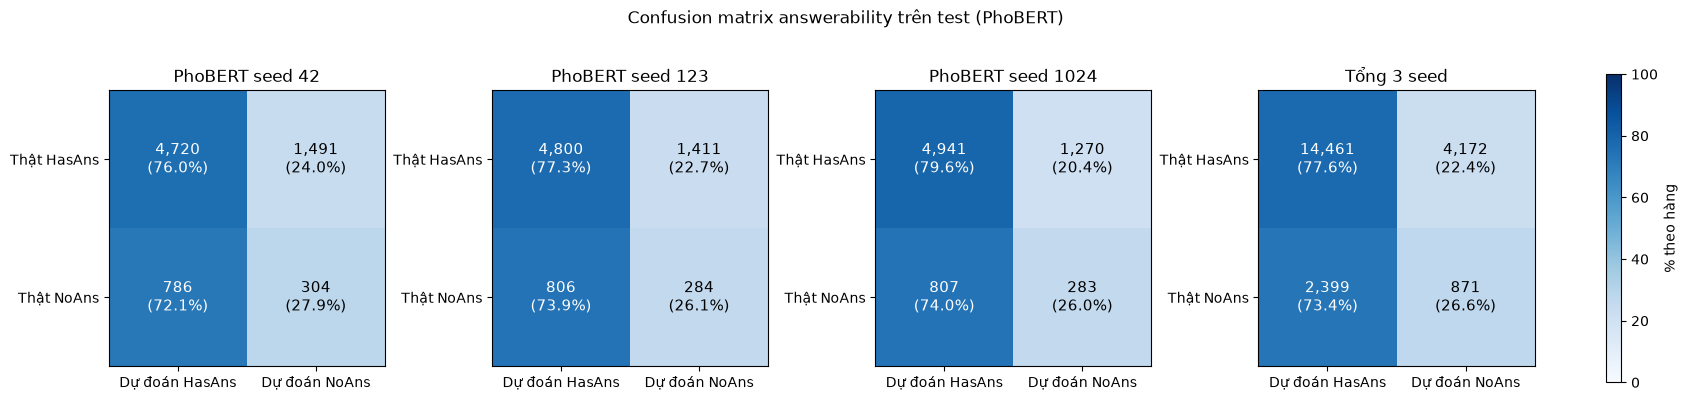

Đã lưu hình: c:\Users\havuh\OneDrive\Desktop\HocTap\Vietnamese_Extractive_Question_Answering_on_UIT_ViQuAD_2.0_Project\results\test\confusion_matrices.png


In [5]:
import matplotlib.pyplot as plt

class_names = ["HasAns", "NoAns"]
panels = [(f"PhoBERT seed {s}", np.array(method_metrics[f"PhoBERT seed {s}"]["confusion_matrix"])) for s in SEEDS]
panels.append(("Tổng 3 seed", sum(matrix for _, matrix in panels)))

fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.2), constrained_layout=True)
for ax, (title, matrix) in zip(axes, panels):
    row_pct = 100 * matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{matrix[r, c]:,}\n({row_pct[r, c]:.1f}%)", ha="center", va="center",
                    color="white" if row_pct[r, c] > 55 else "black", fontsize=11)
    ax.set_xticks([0, 1], [f"Dự đoán {n}" for n in class_names])
    ax.set_yticks([0, 1], [f"Thật {n}" for n in class_names])
    ax.set_title(title)
fig.colorbar(image, ax=axes, shrink=0.8, label="% theo hàng")
fig.suptitle("Confusion matrix answerability trên test (PhoBERT)")
figure_path = results_dir / "test" / "confusion_matrices.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=200)
plt.show()
print("Đã lưu hình:", figure_path)

## Bước 5 — Lưu kết quả

In [6]:
output = {
    "split": "test",
    "test_file": test_path.name,
    "test_sha256": test_sha256,
    "sample_count": len(test_ids),
    "has_answer_count": len(test_ids) - test_noans,
    "no_answer_count": test_noans,
    "dev_no_answer_rate_percent": 100 * dev_noans / len(dev_examples),
    "test_no_answer_rate_percent": 100 * test_noans / len(test_ids),
    "train_dev_test_duplicate_pairs": leaked,
    "no_answer_rule": 'prediction_text == ""',
    "confusion_matrix_order": {"rows": ["true_HasAns", "true_NoAns"],
                               "columns": ["predicted_HasAns", "predicted_NoAns"]},
    "finetune_experiment_ids": {"phobert": "results/finetune/phobert"},
    "std_ddof": 0,
    "reference_always_answer": always_answer,
    "methods": method_metrics,
    "finetune_summary": architecture_summary,
    "prediction_files_dir": str(pred_dir.relative_to(project_root)),
}
output_path = results_dir / "test_answerability_metrics.json"
save_json(output_path, output)
print("Đã lưu:", output_path)

Đã lưu: c:\Users\havuh\OneDrive\Desktop\HocTap\Vietnamese_Extractive_Question_Answering_on_UIT_ViQuAD_2.0_Project\results\test_answerability_metrics.json


## Cách đọc kết quả

- **Accuracy** là tỷ lệ quyết định có/không có đáp án đúng trên cả hai lớp. Test chủ yếu là câu có đáp án nên mô hình luôn trả lời cũng đạt accuracy cao (dòng tham chiếu); hãy đọc accuracy cạnh dòng đó.
- **Recall NoAns**: tỷ lệ câu không có đáp án thật được nhận ra. **Precision NoAns**: trong các câu bị từ chối, tỷ lệ đúng là không có đáp án. **Recall HasAns**: mô hình có bỏ sót câu có đáp án hay không.
- **Balanced accuracy** (trung bình recall hai lớp) không phụ thuộc tỷ lệ lớp nên so sánh được giữa dev và test.
- Đây là kết quả test; không dùng nó để chọn lại seed hay ngưỡng.

## Bước 6 — Suy luận XLM-R và mDeBERTa trên cùng tập Test

Dùng đúng ba checkpoint mỗi kiến trúc đã tổng hợp ở notebook 07, với tokenizer nhanh và offset như notebook 04/05. Dùng cấu hình tiền xử lý và batch đánh giá đã lưu theo từng seed. So sánh quyết định có/không đáp án trên 200 mẫu dev với dự đoán đã lưu trước khi suy luận Test. Cache của hai kiến trúc được đặt tên theo lượt huấn luyện, phiên bản tập Test và checkpoint.

In [7]:
from src.data_preprocessing import prepare_validation_features

# Dùng cả nhãn có/không đáp án và đoạn trích tham chiếu từ cùng tệp testing.json.
for example in test_examples:
    answers = example.get("answers")
    references = answers.get("text") if isinstance(answers, dict) else None
    no_answer = example.get("is_impossible")
    if (
        not isinstance(no_answer, bool)
        or not isinstance(references, list)
        or not all(isinstance(text, str) and text.strip() for text in references)
        or bool(references) == no_answer
    ):
        raise ValueError(f"Nhãn hoặc đáp án tham chiếu không hợp lệ cho ID {example['id']}.")

extra_models = {"XLM-R": "xlm-roberta", "mDeBERTa": "mdeberta"}
run_ids = dev_comparison["finetune_experiment_ids"]
checkpoint_info = {}
source_hash = hashlib.sha256(b"".join(
    (project_root / "src" / filename).read_bytes()
    for filename in ("data_preprocessing.py", "evaluation.py")
)).hexdigest()


def predict_fast_qa(tokenizer, model, examples, preprocessing, batch_size):
    batch = {key: [example[key] for example in examples] for key in ("id", "question", "context")}
    features = prepare_validation_features(
        batch,
        tokenizer,
        max_seq_length=preprocessing["max_seq_length"],
        doc_stride=preprocessing["doc_stride"],
    )
    starts, ends = predict_logits(model, features, batch_size=batch_size)
    return decode_predictions(
        starts, ends, features["example_id"], features["offset_mapping"],
        {example["id"]: example for example in examples},
    )


def run_fast_seed(seed_dir, run_metrics):
    model_dir = seed_dir / "best_model"
    tokenizer = AutoTokenizer.from_pretrained(str(model_dir), use_fast=True, local_files_only=True)
    model = AutoModelForQuestionAnswering.from_pretrained(str(model_dir), local_files_only=True).to(device).eval()
    preprocessing = run_metrics["preprocessing"]
    batch_size = run_metrics["training_config"]["per_device_eval_batch_size"]

    # Đối chiếu giống bước PhoBERT. Nếu lệch nhiều, giữ cảnh báo để kiểm tra trước khi báo cáo.
    subset = dev_examples[:200]
    saved = {row["id"]: row["prediction_text"] for row in
             json.loads((seed_dir / "predictions.json").read_text(encoding="utf-8"))}
    fresh = predict_fast_qa(tokenizer, model, subset, preprocessing, batch_size)
    agreement = mean((fresh[row["id"]] == "") == (saved[row["id"]] == "") for row in subset)
    print(f"  Đối chiếu dev (200 mẫu): trùng quyết định rỗng {100 * agreement:.1f}%"
          + ("  <-- CẢNH BÁO: lệch nhiều" if agreement < 0.97 else ""))
    result = predict_fast_qa(tokenizer, model, test_examples, preprocessing, batch_size)
    del model
    if device == "cuda":
        torch.cuda.empty_cache()
    return result


for architecture, model_slug in extra_models.items():
    run_id = run_ids[model_slug]
    for seed in SEEDS:
        method = f"{architecture} seed {seed}"
        seed_dir = results_dir / "finetune" / "runs" / run_id / model_slug / f"seed-{seed}"
        model_dir = seed_dir / "best_model"
        run_metrics = json.loads((seed_dir / "metrics.json").read_text(encoding="utf-8"))
        if run_metrics.get("experiment_id") != run_id or run_metrics.get("seed") != seed:
            raise ValueError(f"Checkpoint {method} không khớp lượt huấn luyện ghi ở notebook 07.")

        # Đổi khóa khi thay nhãn, checkpoint, bộ giải mã hoặc môi trường suy luận.
        model_files = [model_dir / name for name in
                       ("model.safetensors", "config.json", "tokenizer.json", "tokenizer_config.json")]
        cache_inputs = {
            "test": test_sha256, "run": run_id, "source": source_hash,
            "device": device, "torch": str(torch.__version__),
            "bf16": device == "cuda" and torch.cuda.is_bf16_supported(),
            "preprocessing": run_metrics["preprocessing"],
            "batch_size": run_metrics["training_config"]["per_device_eval_batch_size"],
            "files": [(p.name, p.stat().st_size, p.stat().st_mtime_ns) for p in model_files],
        }
        cache_tag = hashlib.sha256(json.dumps(cache_inputs, sort_keys=True).encode()).hexdigest()[:16]
        print(f"{method} | {run_id}")
        get_or_run(method, lambda d=seed_dir, m=run_metrics: run_fast_seed(d, m), cache_tag=cache_tag)
        checkpoint_info[method] = {
            "run_id": run_id,
            "seed": seed,
            "checkpoint": model_dir.relative_to(project_root).as_posix(),
            "cache_tag": cache_tag,
        }

XLM-R seed 42 | run-fe5f5f5b27578bd4


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 899.68it/s]


  Đối chiếu dev (200 mẫu): trùng quyết định rỗng 100.0%
XLM-R seed 42: 7301 mẫu, trả rỗng 1981.
XLM-R seed 123 | run-fe5f5f5b27578bd4


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1064.17it/s]


  Đối chiếu dev (200 mẫu): trùng quyết định rỗng 100.0%
XLM-R seed 123: 7301 mẫu, trả rỗng 2161.
XLM-R seed 1024 | run-fe5f5f5b27578bd4


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 855.06it/s]


... (3 outputs left out)

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 1221.43it/s]


  Đối chiếu dev (200 mẫu): trùng quyết định rỗng 100.0%
mDeBERTa seed 123: 7301 mẫu, trả rỗng 7301.
mDeBERTa seed 1024 | run-a28388a1c7754133


Loading weights: 100%|██████████| 200/200 [00:00<00:00, 900.11it/s]


  Đối chiếu dev (200 mẫu): trùng quyết định rỗng 100.0%
mDeBERTa seed 1024: 7301 mẫu, trả rỗng 3388.


## Bước 7 — So sánh ba kiến trúc trên Test

Accuracy và F1 NoAns đo quyết định có/không đáp án như các bước trước. EM và F1 trích xuất chấm nội dung câu trả lời bằng hàm chung của notebook 07. Bảng ghi từng seed và trung bình +- độ lệch chuẩn (ddof=0). Seed đại diện vẫn được chọn theo Overall F1 trên dev.

Cả ba kiến trúc dùng 7.301 câu từ cùng tệp Test có nhãn bổ sung. Các chỉ số phản ánh chất lượng so với nhãn và đáp án trong tệp này. Giữ nguyên cả hai cặp câu hỏi và ngữ cảnh trùng train/dev để đối chiếu với kết quả PhoBERT của Quy.

In [8]:
from src.evaluation import score_prediction

architectures = ("PhoBERT", *extra_models)
required_methods = [f"{arch} seed {s}" for arch in architectures for s in SEEDS]
test_methods = {}
for method in required_methods:
    predictions = test_predictions[method]
    if set(predictions) != set(test_ids):
        raise ValueError(f"{method} không có đủ dự đoán cho tập Test.")
    texts = [predictions[i] for i in test_ids]
    scores = [score_prediction(text, test_by_id[i]["answers"]["text"]) for i, text in zip(test_ids, texts)]
    test_methods[method] = {
        **answerability_metrics(true_no, [text == "" for text in texts]),
        "overall_em_percent": 100 * mean(em for em, _ in scores),
        "overall_f1_percent": 100 * mean(f1 for _, f1 in scores),
    }

columns = {
    "answerability_accuracy_percent": "Accuracy có/không đáp án (%)",
    "overall_em_percent": "EM trích xuất (%)",
    "overall_f1_percent": "F1 trích xuất (%)",
    "no_answer_precision_percent": "Precision NoAns (%)",
    "no_answer_recall_percent": "Recall NoAns (%)",
    "no_answer_f1_percent": "F1 NoAns (%)",
    "has_answer_recall_percent": "Recall HasAns (%)",
    "balanced_accuracy_percent": "Balanced Accuracy (%)",
}
display(pd.DataFrame([
    {"Mô hình / seed": method, **{label: m[key] for key, label in columns.items()},
     "Ma trận [[HH,HN],[NH,NN]]": str(m["confusion_matrix"])}
    for method, m in test_methods.items()
]).round(2))

test_summary = {}
summary_table = []
for arch in architectures:
    selected = max(SEEDS, key=lambda s: (dev_methods[f"{arch} seed {s}"]["overall_f1_percent"], -s))
    stats = {}
    for key in columns:
        values = [test_methods[f"{arch} seed {s}"][key] for s in SEEDS]
        stats[key] = {"mean": mean(values), "std": pstdev(values), "per_seed": dict(zip(map(str, SEEDS), values))}
    test_summary[arch] = {
        "seeds": list(SEEDS),
        "dev_selected_seed": selected,
        "metrics": stats,
        "dev_selected_seed_metrics": test_methods[f"{arch} seed {selected}"],
    }
    summary_table.append({
        "Kiến trúc": arch,
        "Seed chọn theo dev": selected,
        **{label: f"{stats[key]['mean']:.2f} +- {stats[key]['std']:.2f}" for key, label in columns.items()},
    })
display(pd.DataFrame(summary_table))

comparison_path = results_dir / "test_architecture_comparison.json"
save_json(comparison_path, {
    **output,
    "finetune_experiment_ids": {**output["finetune_experiment_ids"], **run_ids},
    "checkpoints": checkpoint_info,
    "methods": test_methods,
    "finetune_summary": test_summary,
})
print("Đã lưu bảng so sánh:", comparison_path)

,Mô hình / seed,Accuracy có/không đáp án (%),EM trích xuất (%),F1 trích xuất (%),Precision NoAns (%),Recall NoAns (%),F1 NoAns (%),Recall HasAns (%),Balanced Accuracy (%),"Ma trận [[HH,HN],[NH,NN]]"
0,PhoBERT seed 42,68.81,4.56,19.06,16.94,27.89,21.07,75.99,51.94,"[[4720, 1491], [786, 304]]"
1,PhoBERT seed 123,69.63,4.30,18.82,16.76,26.06,20.39,77.28,51.67,"[[4800, 1411], [806, 284]]"
2,PhoBERT seed 1024,71.55,4.37,19.55,18.22,25.96,21.42,79.55,52.76,"[[4941, 1270], [807, 283]]"
3,XLM-R seed 42,67.28,4.82,18.86,17.21,31.28,22.21,73.60,52.44,"[[4571, 1640], [749, 341]]"
4,XLM-R seed 123,65.58,5.26,19.14,17.08,33.85,22.70,71.15,52.50,"[[4419, 1792], [721, 369]]"
5,XLM-R seed 1024,58.14,7.14,18.67,17.08,46.79,25.02,60.14,53.46,"[[3735, 2476], [580, 510]]"
6,mDeBERTa seed 42,14.93,14.93,14.93,14.93,100.00,25.98,0.00,50.00,"[[0, 6211], [0, 1090]]"
7,mDeBERTa seed 123,14.93,14.93,14.93,14.93,100.00,25.98,0.00,50.00,"[[0, 6211], [0, 1090]]"
8,mDeBERTa seed 1024,53.10,7.44,12.14,15.55,48.35,23.54,53.94,51.14,"[[3350, 2861], [563, 527]]"


,Kiến trúc,Seed chọn theo dev,Accuracy có/không đáp án (%),EM trích xuất (%),F1 trích xuất (%),Precision NoAns (%),Recall NoAns (%),F1 NoAns (%),Recall HasAns (%),Balanced Accuracy (%)
0,PhoBERT,1024,70.00 +- 1.15,4.41 +- 0.11,19.14 +- 0.30,17.30 +- 0.65,26.64 +- 0.89,20.96 +- 0.42,77.61 +- 1.47,52.12 +- 0.46
1,XLM-R,42,63.67 +- 3.97,5.74 +- 1.00,18.89 +- 0.19,17.12 +- 0.06,37.31 +- 6.78,23.31 +- 1.23,68.29 +- 5.85,52.80 +- 0.47
2,mDeBERTa,42,27.65 +- 17.99,12.43 +- 3.53,14.00 +- 1.31,15.14 +- 0.29,82.78 +- 24.35,25.17 +- 1.15,17.98 +- 25.43,50.38 +- 0.54


Đã lưu bảng so sánh: c:\Users\havuh\OneDrive\Desktop\HocTap\Vietnamese_Extractive_Question_Answering_on_UIT_ViQuAD_2.0_Project\results\test_architecture_comparison.json
